In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [67]:
df = pd.read_csv("/content/student_sleep_mental_health_2026.csv")

In [68]:
df.sample(5)

,student_id,age,gender,education_level,avg_sleep_hours,screen_time_hours,social_media_hours,study_hours_per_day,exercise_hours_per_week,caffeine_drinks_per_day,stress_level,anxiety_score,gpa,uses_sleep_app,feels_burned_out
2747,2748,15,Male,Undergraduate,7.0,10.1,4.6,4.4,3.4,1,9,10,2.96,False,True
901,902,20,Female,High School,7.6,7.3,5.7,1.8,2.1,0,7,6,3.20,False,True
189,190,16,Male,High School,8.8,8.4,2.2,2.0,0.6,2,7,9,3.97,False,True
2262,2263,19,Prefer not to say,Undergraduate,7.6,5.9,3.9,4.5,6.7,3,4,6,3.87,True,False
2508,2509,16,Male,High School,8.4,4.3,2.1,3.7,0.0,3,6,4,3.49,False,False


In [69]:
df.shape # 3000 rows, 15 columns

(3000, 15)

In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   student_id               3000 non-null   int64  
 1   age                      3000 non-null   int64  
 2   gender                   3000 non-null   object 
 3   education_level          3000 non-null   object 
 4   avg_sleep_hours          3000 non-null   float64
 5   screen_time_hours        3000 non-null   float64
 6   social_media_hours       3000 non-null   float64
 7   study_hours_per_day      3000 non-null   float64
 8   exercise_hours_per_week  3000 non-null   float64
 9   caffeine_drinks_per_day  3000 non-null   int64  
 10  stress_level             3000 non-null   int64  
 11  anxiety_score            3000 non-null   int64  
 12  gpa                      3000 non-null   float64
 13  uses_sleep_app           3000 non-null   bool   
 14  feels_burned_out        

In [71]:
# no null values , all cleaned.

In [72]:
df.isnull().sum() # no null valued columnsprint

df.duplicated().sum() # no duplicate values

np.int64(0)

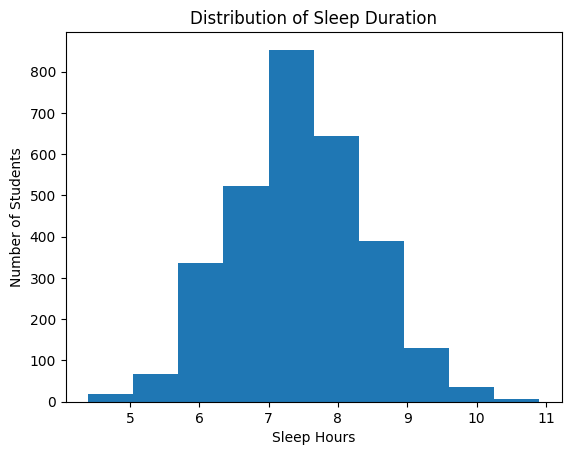

In [73]:
plt.hist(df["avg_sleep_hours"], bins=10)
plt.title("Distribution of Sleep Duration")
plt.xlabel("Sleep Hours")
plt.ylabel("Number of Students")

plt.show()

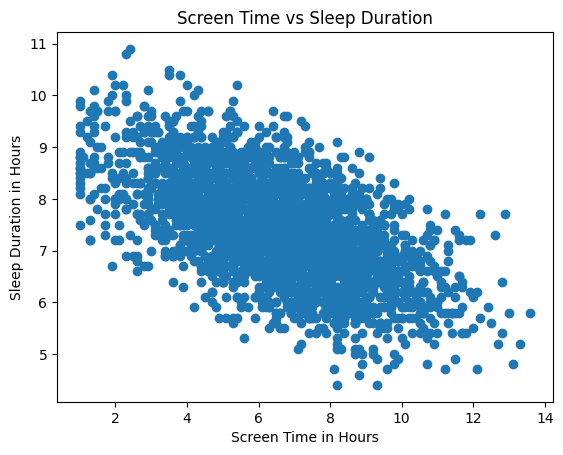

In [74]:
plt.scatter(
    df["screen_time_hours"],
    df["avg_sleep_hours"])

plt.title("Screen Time vs Sleep Duration")
plt.xlabel("Screen Time in Hours")
plt.ylabel("Sleep Duration in Hours")

plt.show()

In [75]:
correlation = df[["avg_sleep_hours", "screen_time_hours","stress_level", "anxiety_score", "gpa"]].corr()

display(correlation)

,avg_sleep_hours,screen_time_hours,stress_level,anxiety_score,gpa
avg_sleep_hours,1.000000,-0.587266,-0.495939,-0.360881,0.522262
screen_time_hours,-0.587266,1.000000,0.528283,0.377056,-0.491977
stress_level,-0.495939,0.528283,1.000000,0.738170,-0.558041
anxiety_score,-0.360881,0.377056,0.738170,1.000000,-0.383876
gpa,0.522262,-0.491977,-0.558041,-0.383876,1.000000


# **Exploratory Data Analysis**

In [76]:
print("Gender distribution:")
print()
display(df["gender"].value_counts().reset_index())

print("Education level:")
display(df["education_level"].value_counts().reset_index())

Gender distribution:



,gender,count
0,Female,1410
1,Male,1406
2,Non-binary,110
3,Prefer not to say,74


Education level:


,education_level,count
0,Undergraduate,1681
1,High School,889
2,Graduate,430


In [77]:
df.groupby("feels_burned_out")["avg_sleep_hours"].agg(["count", "mean", "median"]).reset_index()

,feels_burned_out,count,mean,median
0,False,961,7.960666,8.0
1,True,2039,7.156449,7.2


In [78]:
# this suggests that , most of the students feel burnt out.
#Further analysis is required to determine

In [82]:
correlation = df["screen_time_hours"].corr(df["anxiety_score"])
print(correlation)

# postive but weak correlation between screen time hours and anxiety score.
#Further analysis is required to determine any conclusions.

0.3770562643965783


In [92]:
corr = df["study_hours_per_day"].corr(df["gpa"])
corr

#study hours per day show a negligible linear association with GPA
#Further analysis is required to determine any conclusions.

np.float64(0.001791637346889139)